# Road to Safety — Exploratory descriptive analysis

## tl;dr

The selected 1999–2021 releases contain **2,949,846 candidate fatal/injury collisions**, including **47,793 fatal collisions (1.620%)**. Friday and 16:00 have the largest collision counts; Sunday and 02:00 have the highest pooled weekday/hour fatal proportions. Summer has the largest seasonal collision count and fatal proportion.

Visibility limitation has a 2.819% fatal proportion, compared with 1.596% for clear/sunny conditions. These are **unadjusted conditional severity associations**. They do not measure crash occurrence or establish causal effects.

Requiring numeric stated values for all eight features would discard **571,546 collisions (19.3755%)**. Unknown and other categories remain separate, and no records are removed. Small annual cells and the distinct 2020–2021 patterns warrant year-aware modeling.

Full tables and reasoning: [combined findings](../docs/descriptive_analysis.md), [temporal](../docs/temporal_findings.md), [conditions](../docs/condition_findings.md), [quality/stability](../docs/stability_findings.md).

## Context & Methods

This is descriptive analysis at the prepared candidate-collision grain, for road safety analysts preparing severity baselines. The target is fatal versus nonfatal injury collision, conditional on appearing in these archived NCDB releases. Every candidate currently has an eligible target.

### Key Assumptions

- One selected release per collision year, keyed by `(source_id, C_YEAR, C_CASE)`; case semantics remain undocumented.
- Fatal proportion = fatal collisions / eligible fatal-or-injury collisions in the displayed group. This is not a per-person death probability, exposure rate, or accident likelihood.
- Calendar months define meteorological seasons: DJF, MAM, JJA, SON. Winter is a month grouping within source years, not a continuous cross-year winter cohort. No duration/travel normalization is possible.
- Monday=1, Sunday=7; hour00 is midnight. Source hours have no timezone conversion.
- Unknown (`U/UU`), other (`Q/QQ`), jurisdiction unavailable (`X/XX`) and conflicts remain separate. Stated-category temporal panels omit non-stated values only from those figures and disclose their counts; evidence tables retain them.
- Sparse flag: group n<100 **or** fatal count<5; warning only. Zero-observation groups have undefined fatal proportions.
- Condition Wilson95% intervals describe binomial precision; they are not design-based uncertainty for all Canadian collisions. Year-standardization changes year weights only, not confounding by road type, location or participants.
- No geography, exposure, non-crash controls or full calendar dates. Publication aggregates are separate source vintages and are not appended.

The notebook regenerates the CSVs and figures from read-only Parquet, checks input fingerprints, and independently reconciles counts. Plotting implementations are in the three editable `src/road_to_safety/analyze_*.py` modules. Run from this directory or the project root with the locked project `.venv` kernel (`uv sync --locked --extra notebook`).

## Data

### 1. Locate the project and validate inputs

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from road_to_safety.explore import verify_inputs
from road_to_safety import analyze_temporal, analyze_conditions, analyze_stability
from road_to_safety.validate_exploration import validate

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'data/derived/collisions.parquet').exists()
receipt = verify_inputs(ROOT)
print(f"Validated cohort: {receipt['collisions']:,} collisions; {receipt['fatal_collisions']:,} fatal")
print('Input: data/derived/collisions.parquet; selected annual NCDB releases, 1999–2021')
print('SHA256:', receipt['input_fingerprints']['data/derived/collisions.parquet'])

Validated cohort: 2,949,846 collisions; 47,793 fatal
Input: data/derived/collisions.parquet; selected annual NCDB releases, 1999–2021
SHA256: 32b62f217040e2a4ca30d76faabf495e13cbe77ed7aef732f0e413ba3a34f0de


### 2. Recompute evidence and independently reconcile

In [2]:
for producer in (analyze_temporal, analyze_conditions, analyze_stability):
    producer.run(ROOT)
validation = validate(ROOT)
assert validation['status'] == 'passed', validation['failures']
print(f"{len(validation['checks_passed'])} independent checks passed.")
print('CSV evidence: reports/tables/eda_*.csv; figures: reports/figures/*.png')

def table(name):
    return pd.read_csv(ROOT / 'reports/tables' / name)

def figure(name):
    display(Image(filename=str(ROOT / 'reports/figures' / name), width=1000))

32 independent checks passed.
CSV evidence: reports/tables/eda_*.csv; figures: reports/figures/*.png


## Results

### Annual patterns

Counts and fatal proportions use separate panels and scales. The 2020 denominator falls much more than its fatal count: case mix and reporting/exposure changes cannot be separated here.

,C_YEAR,collisions,fatal_collisions,fatal_proportion
0,1999,151315,2632,0.017394
1,2000,155838,2548,0.016350
2,2001,151438,2415,0.015947
3,2002,156415,2583,0.016514
4,2003,152980,2487,0.016257
5,2004,147588,2438,0.016519
6,2005,148111,2551,0.017224
7,2006,145103,2586,0.017822
8,2007,141070,2455,0.017403
9,2008,129764,2193,0.016900


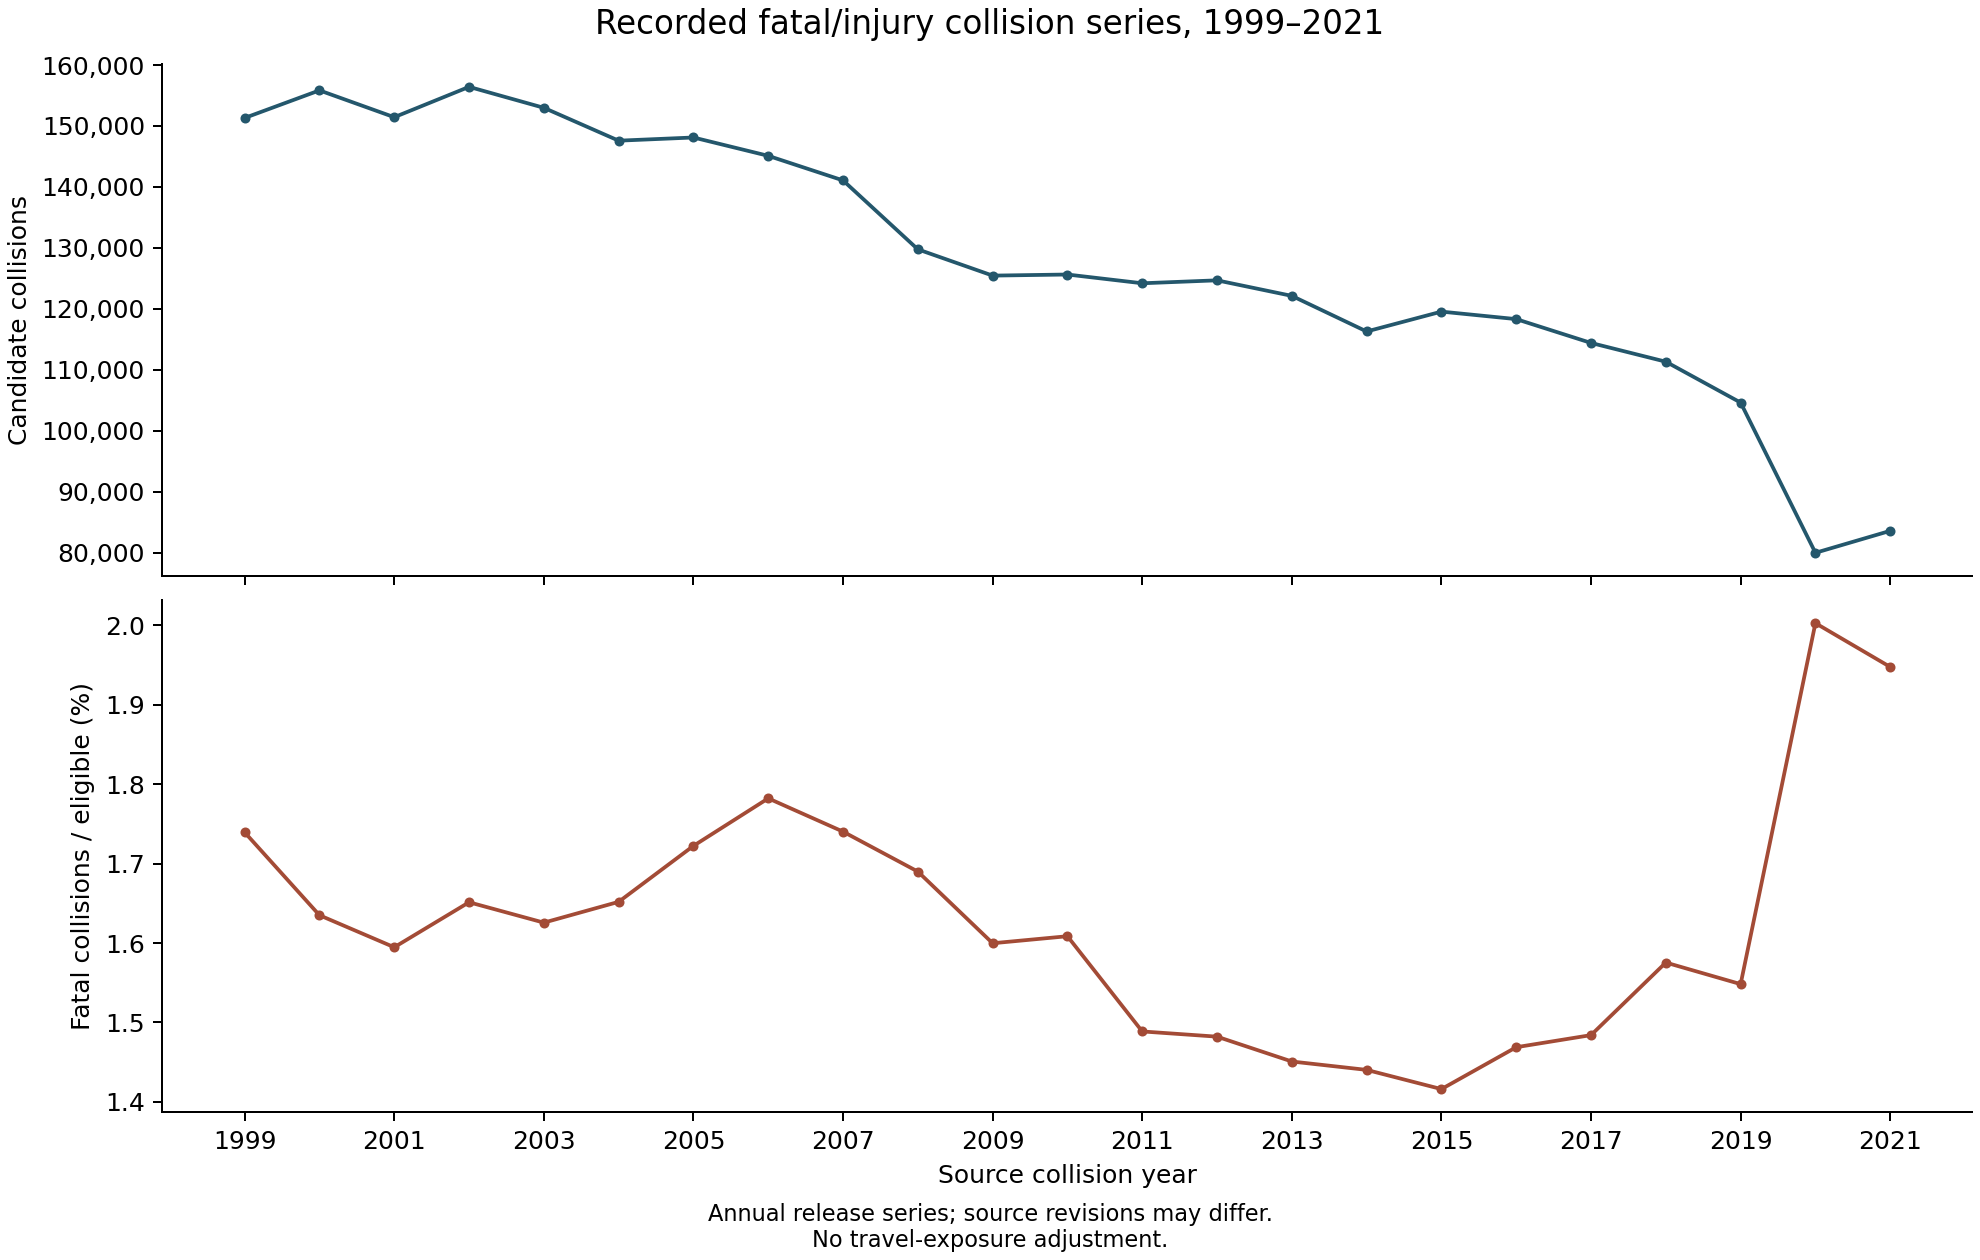

In [3]:
display(table('eda_temporal_annual.csv')[['C_YEAR','collisions','fatal_collisions','fatal_proportion']])
figure('temporal_annual.png')

### Calendar month

August has the largest pooled monthly count. Month lengths and travel volumes differ; raw counts are not daily rates.

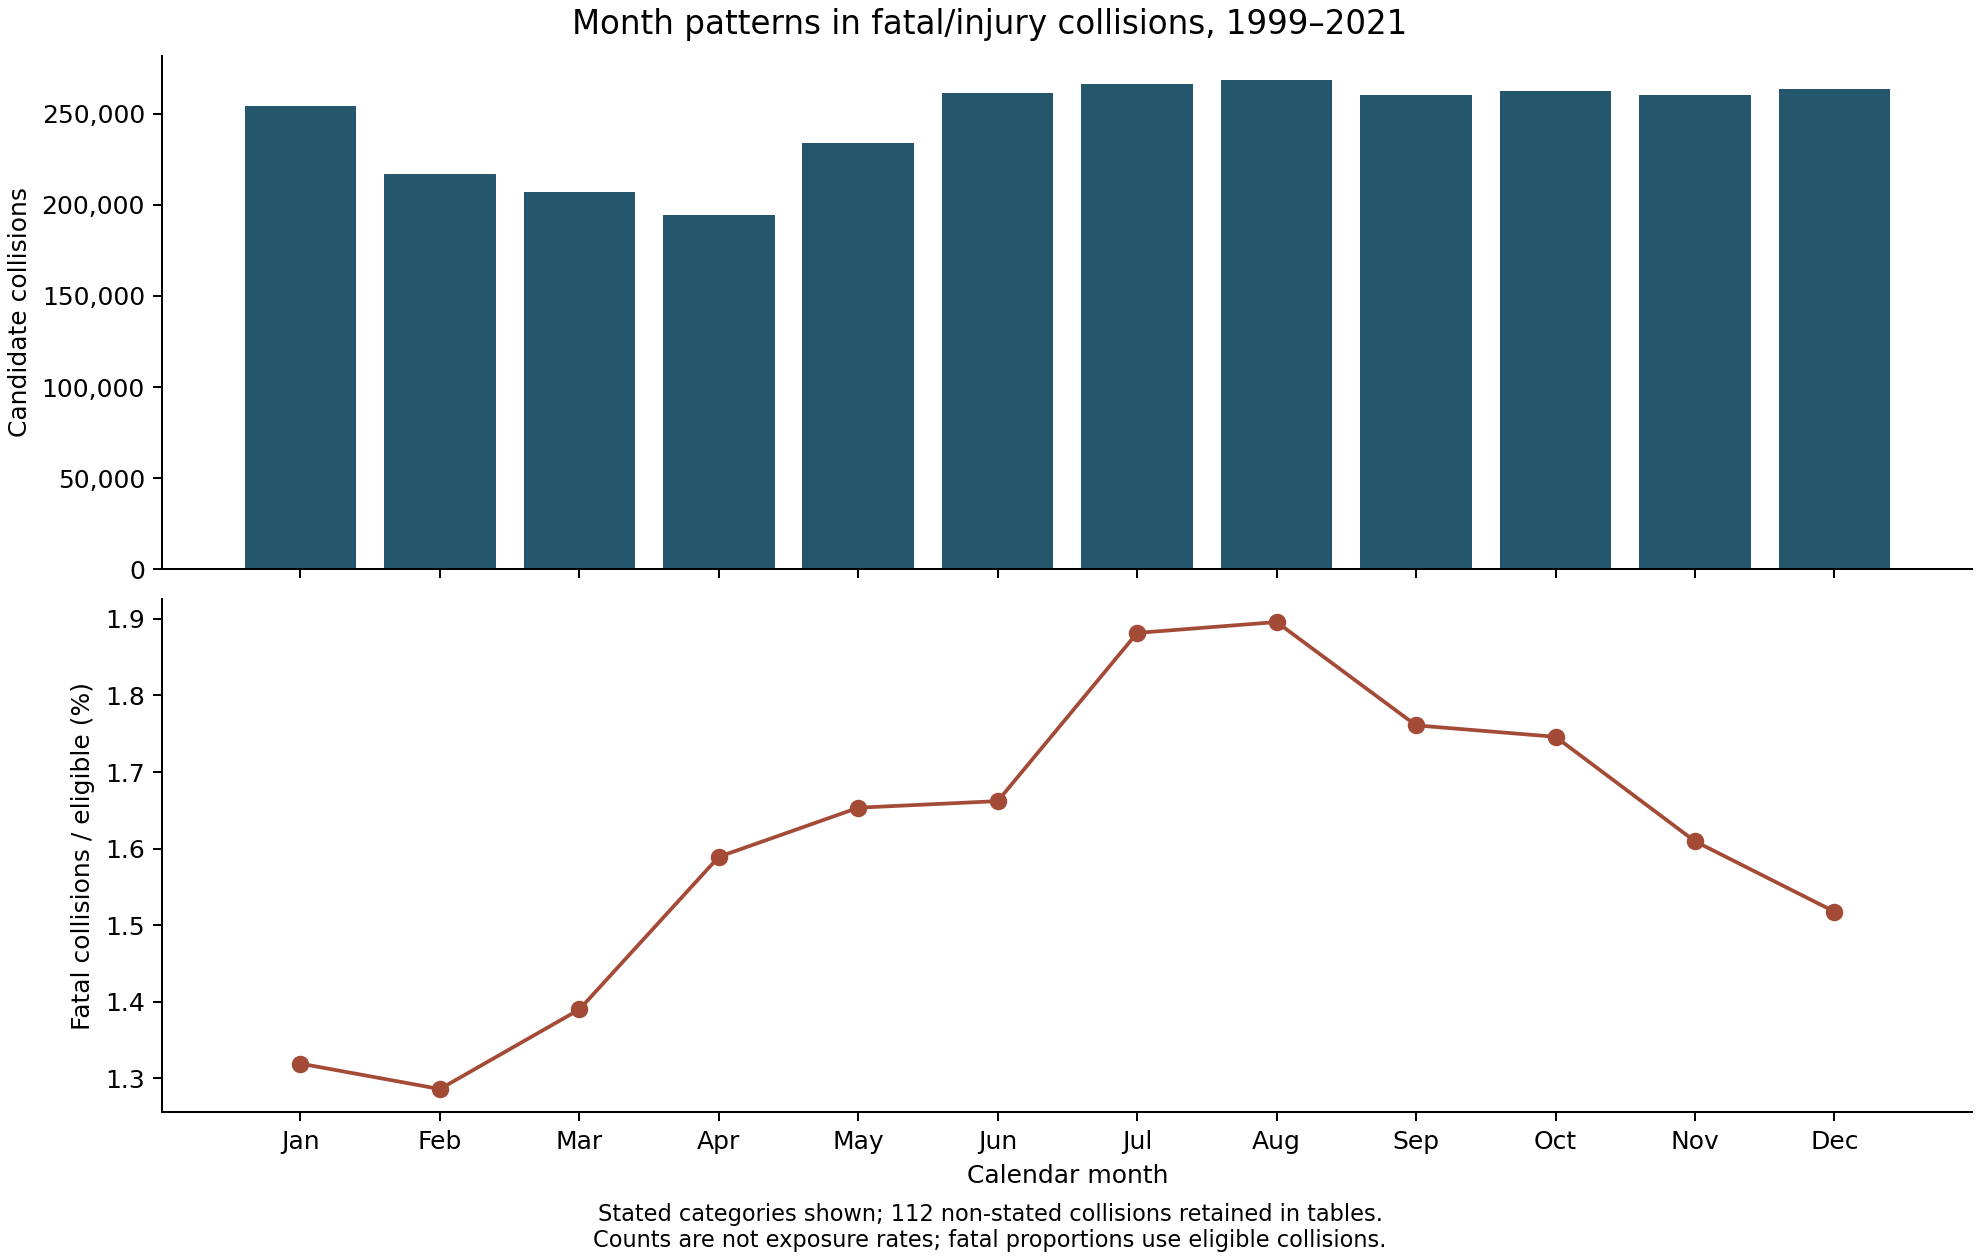

In [4]:
figure('temporal_month.png')

### Meteorological season

Summer has 796,187 collisions and a 1.814% fatal proportion; winter month grouping is not an exposure-adjusted comparison.

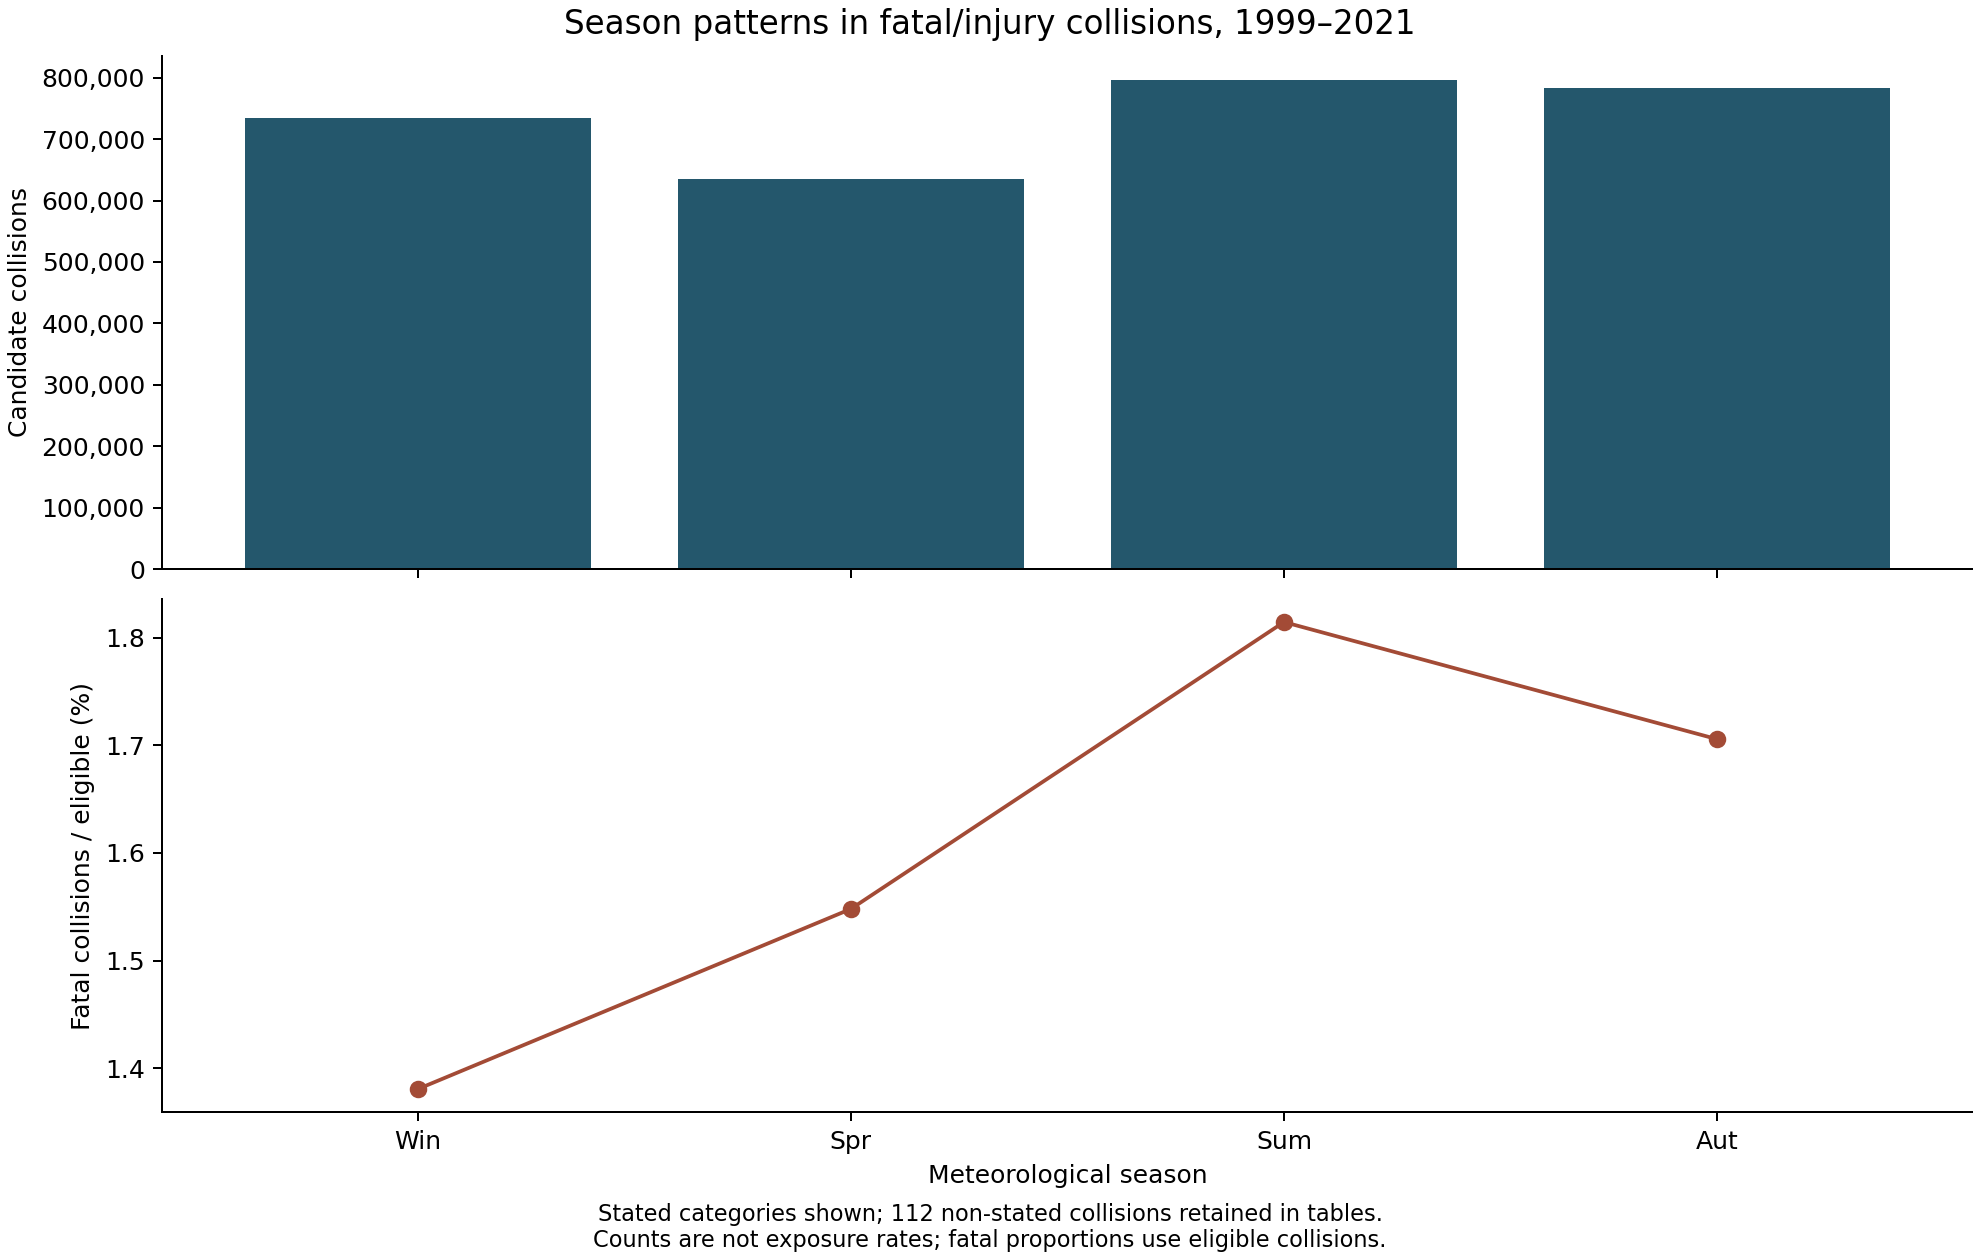

In [5]:
figure('temporal_season.png')

### Reported weekday

Friday has 496,697 collisions; Sunday has the highest pooled weekday fatal proportion, 2.148%.

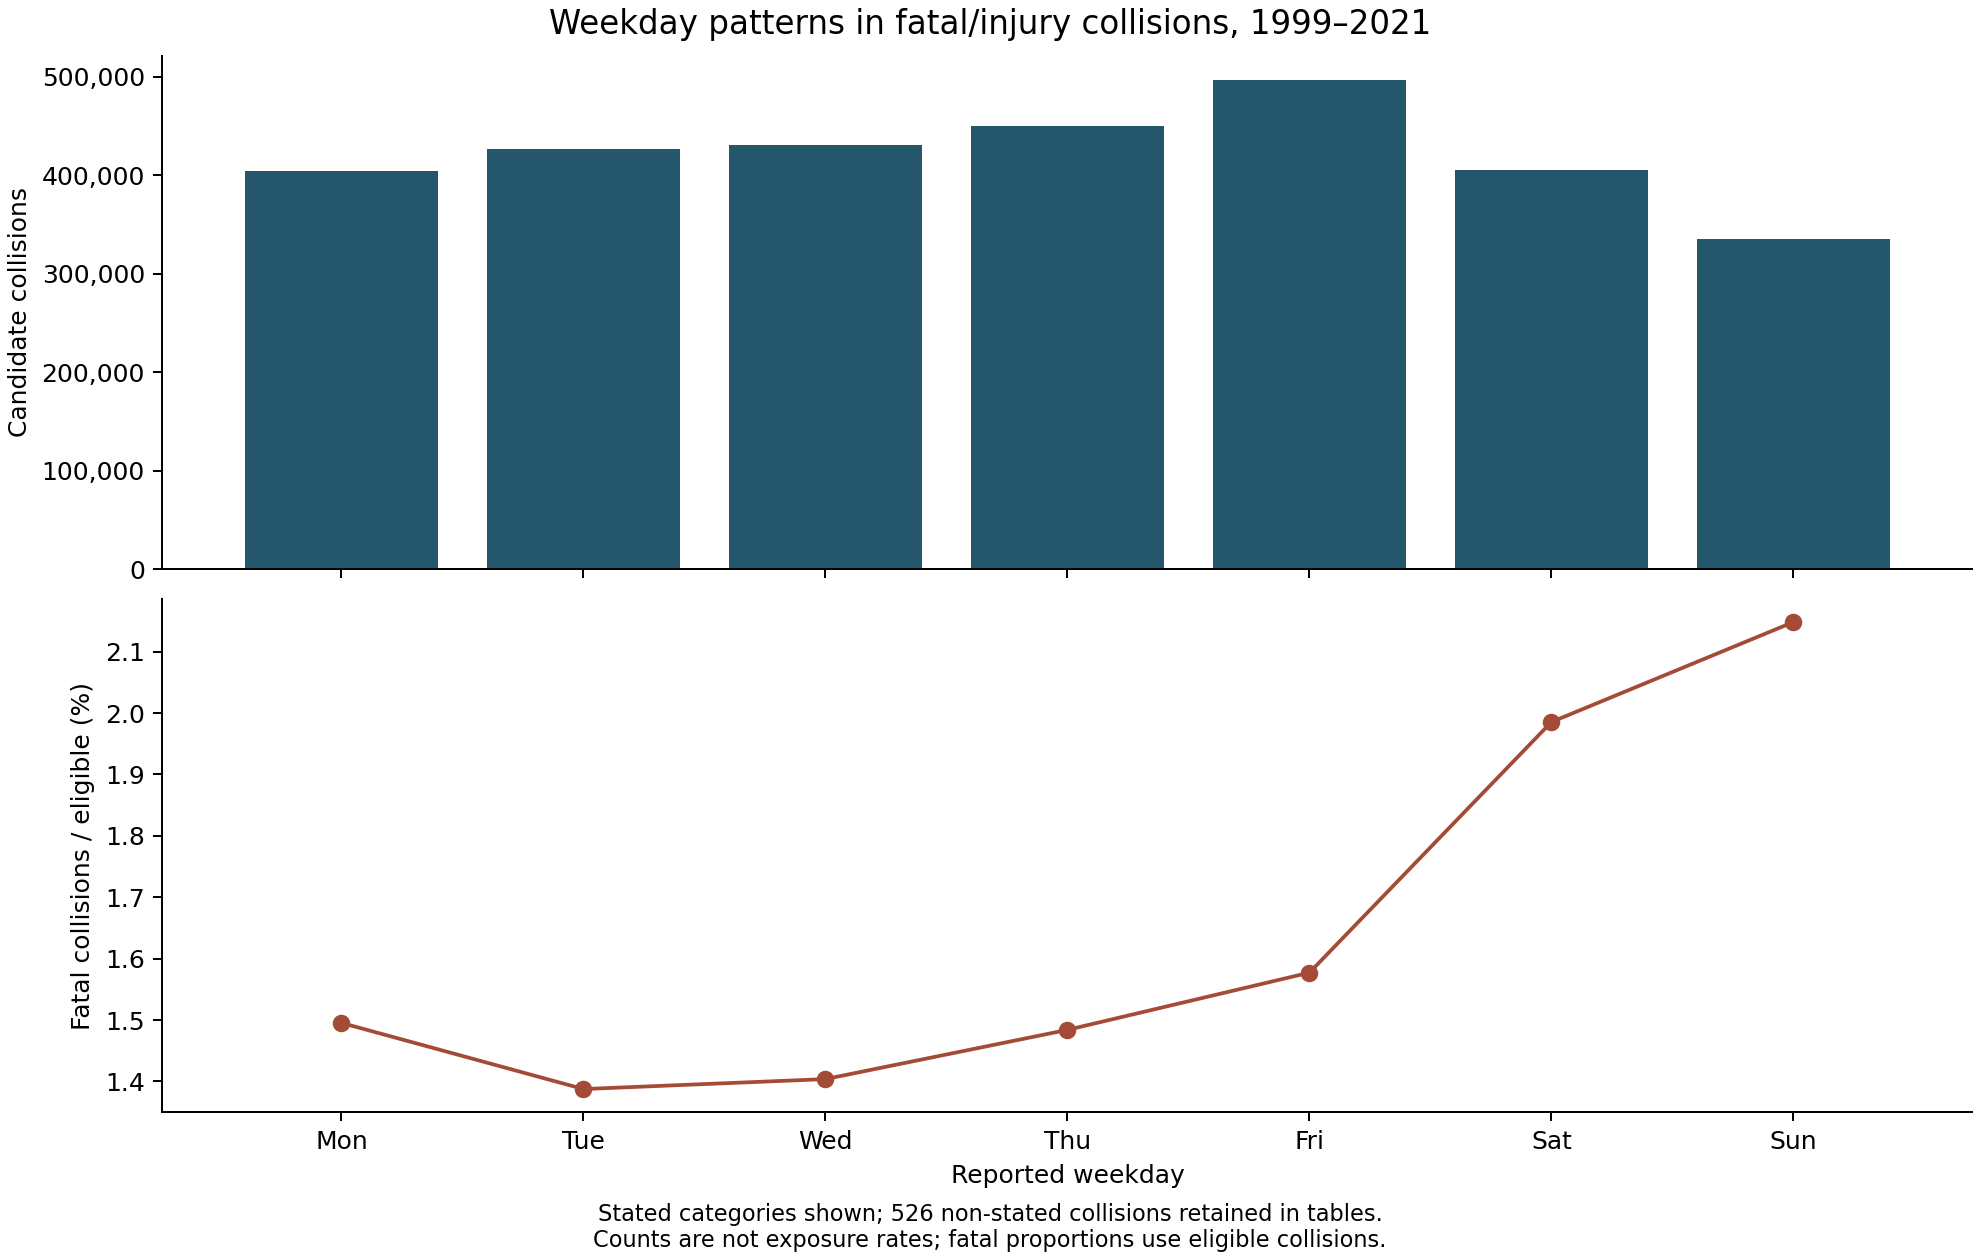

In [6]:
figure('temporal_weekday.png')

### Reported hour

16:00 has 249,337 collisions; 02:00 has the highest hourly fatal proportion, 3.915%. Greater conditional severity does not establish greater crash probability.

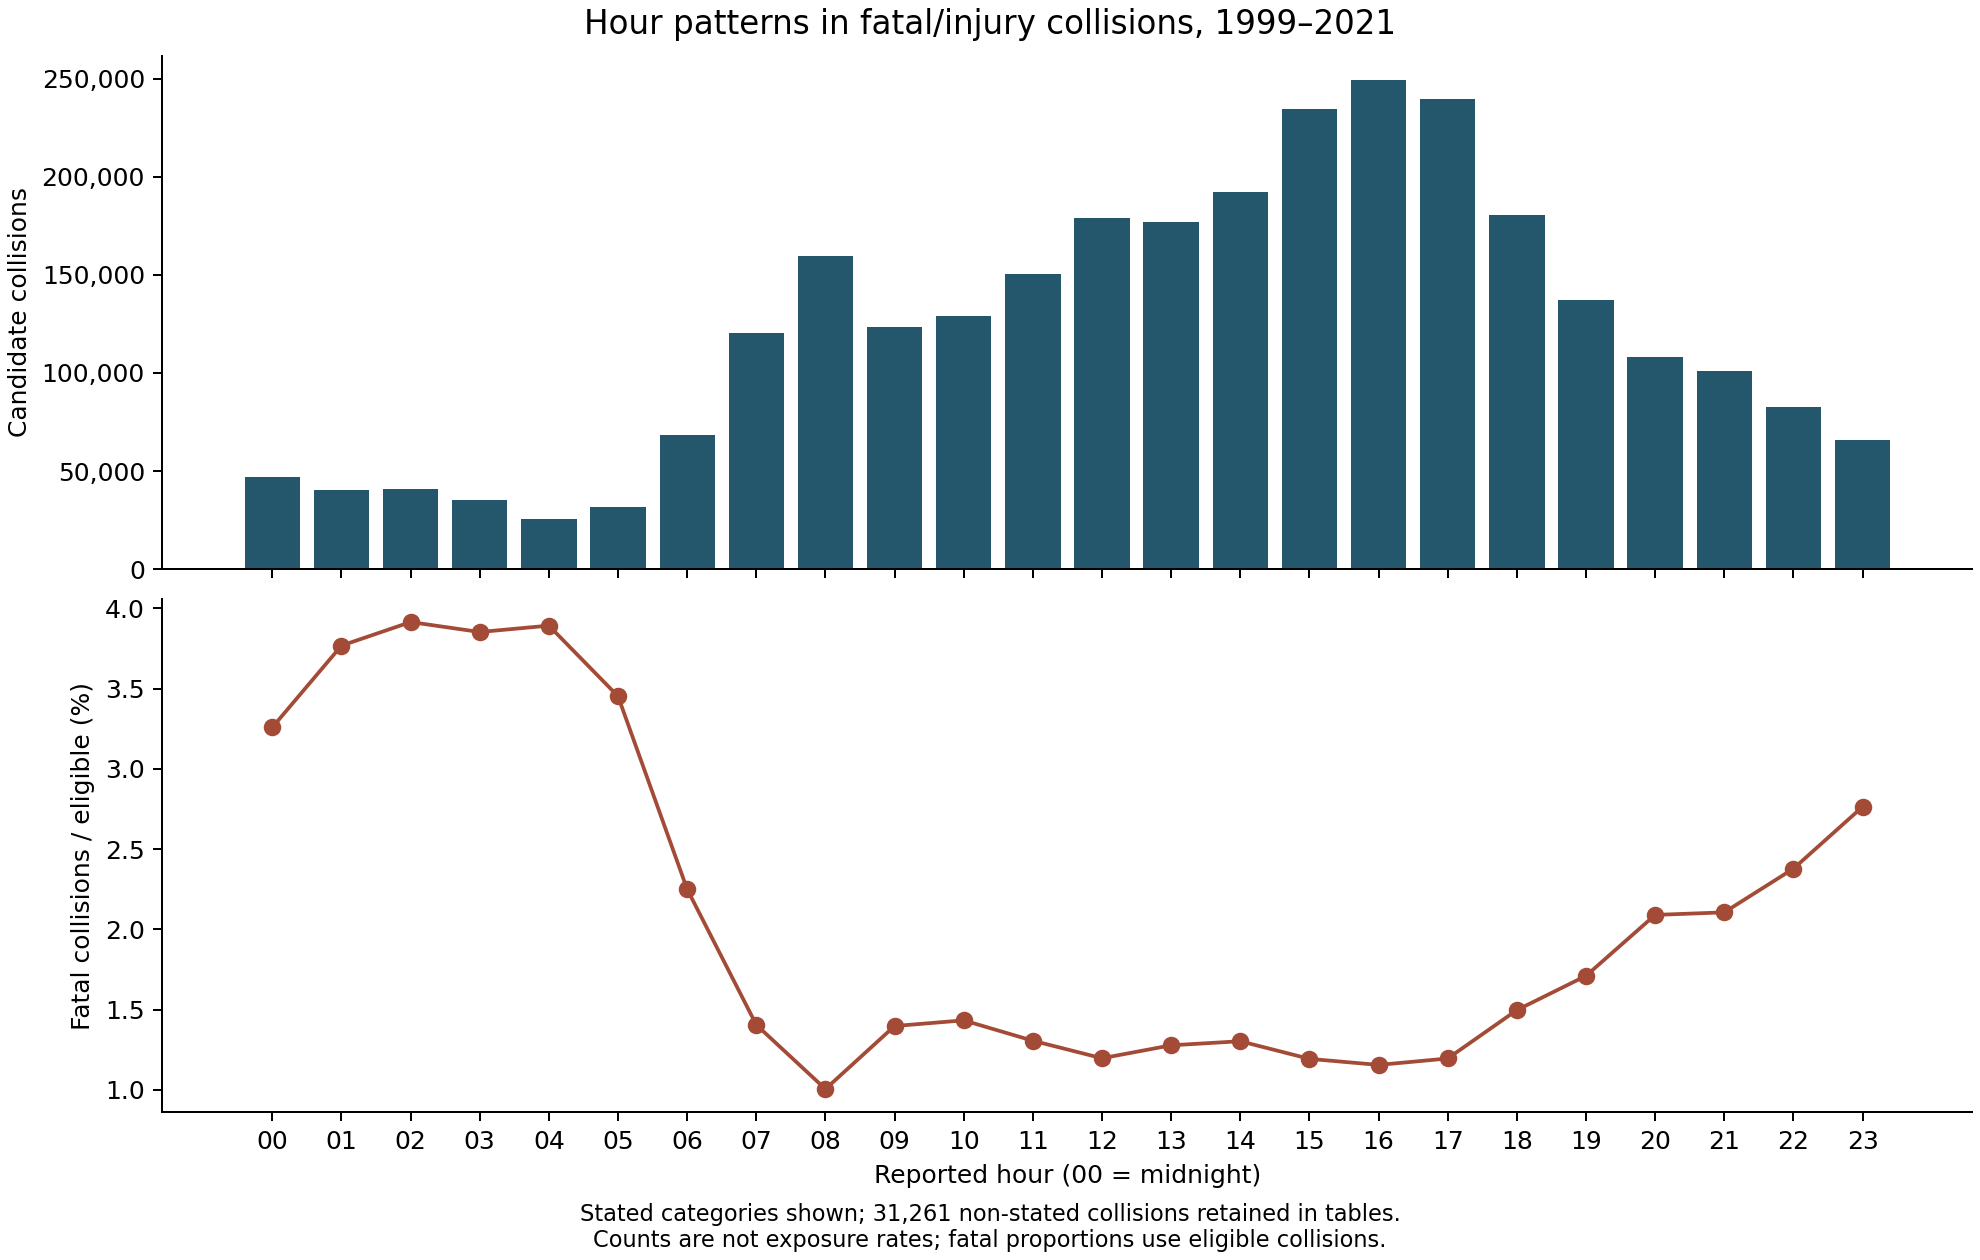

In [7]:
figure('temporal_hour.png')

### Weekday–hour pattern

Both fields are stated for 2,918,220 collisions. All 168 displayed cells exceed the sparse thresholds; 31,626 collisions remain in evidence tables outside these heatmaps.

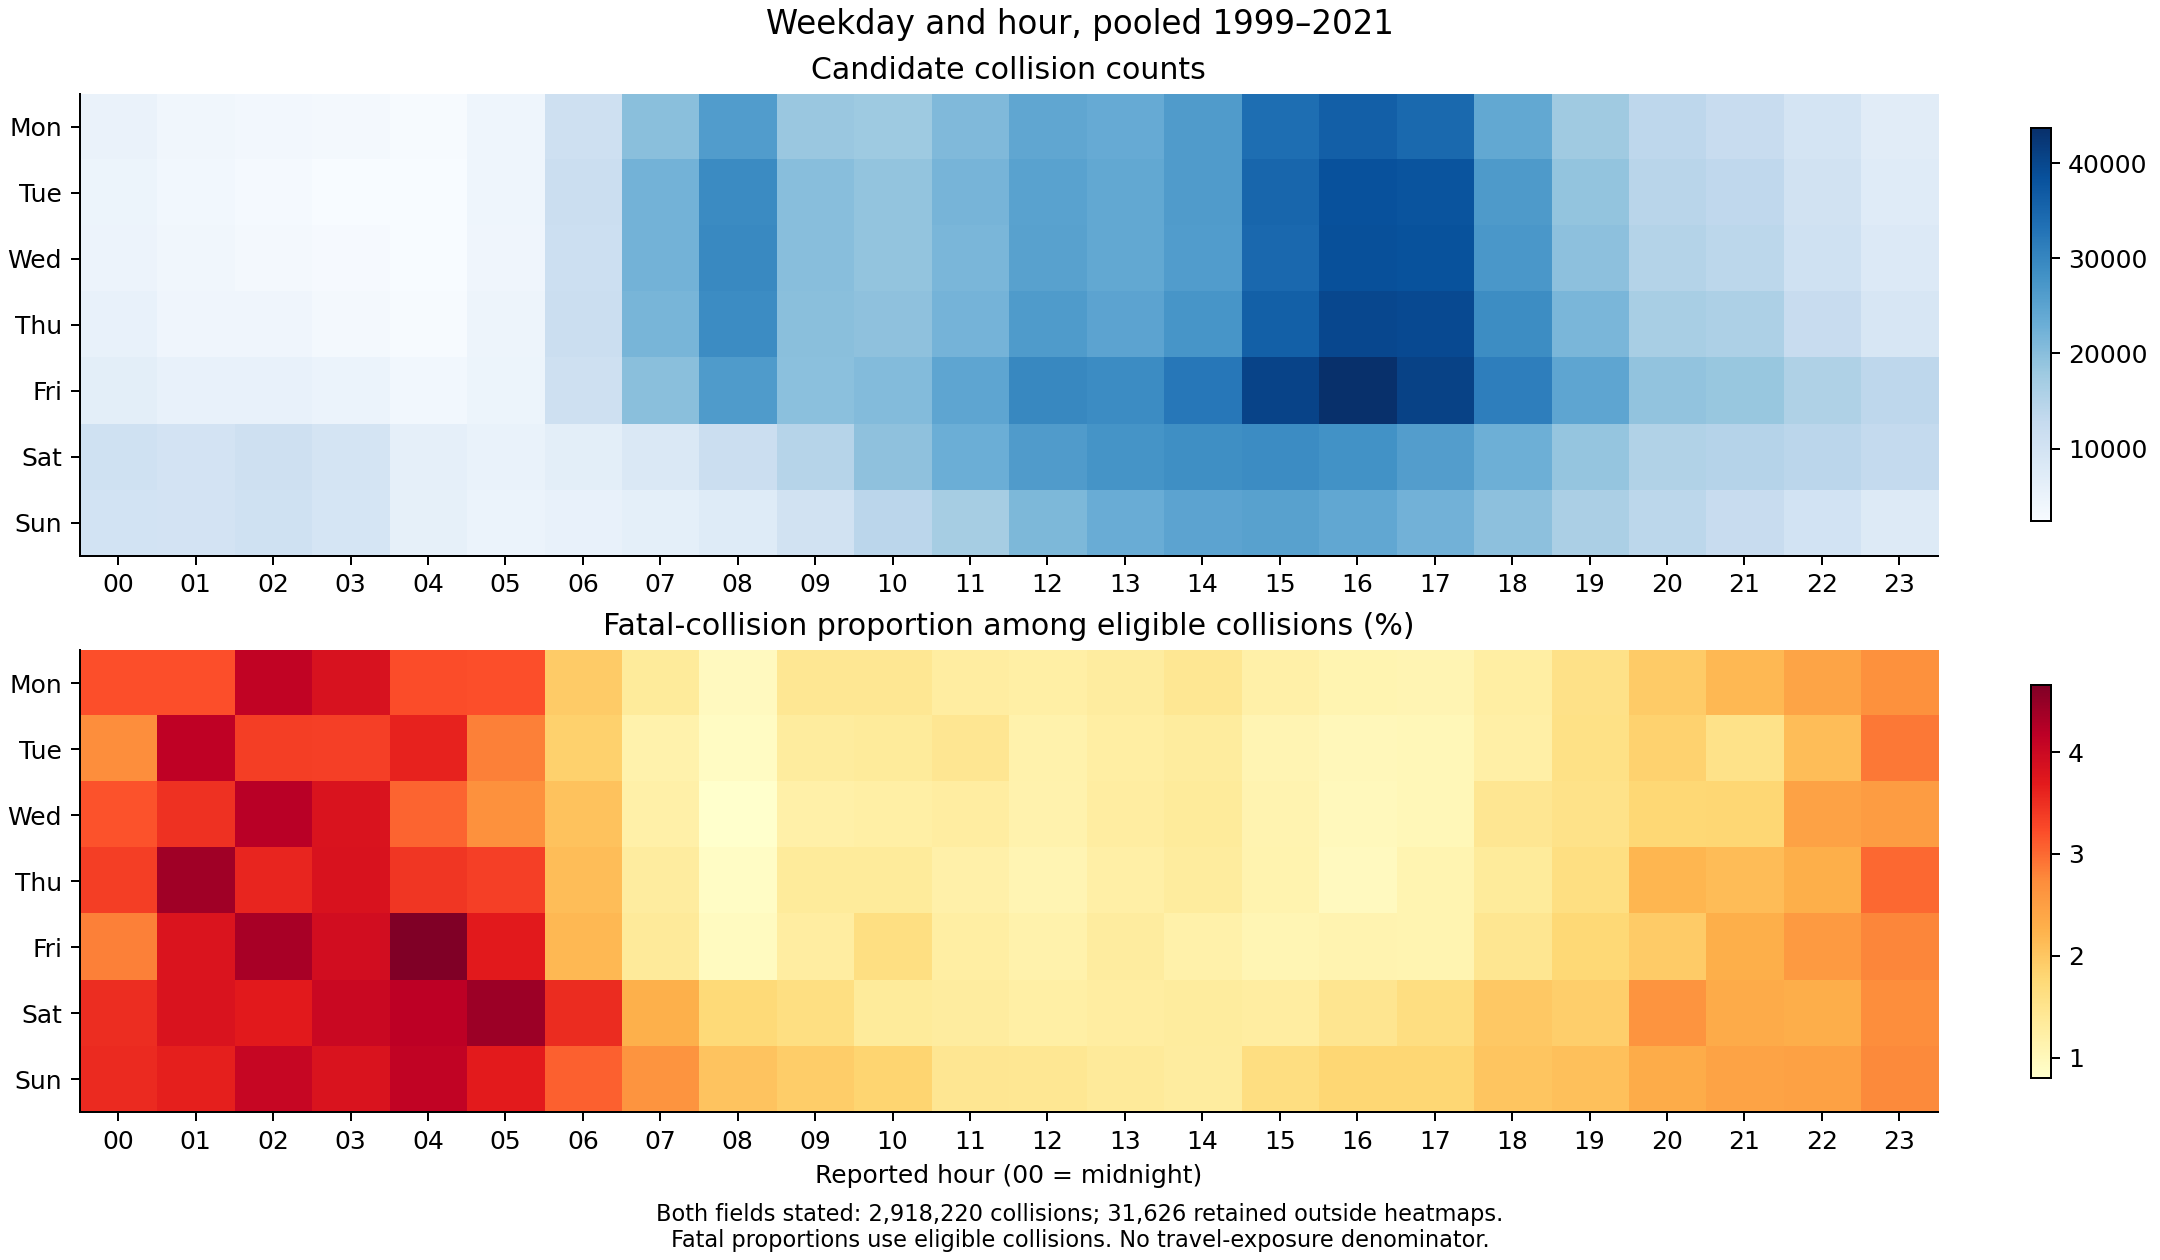

In [8]:
figure('temporal_weekday_hour.png')

### Weather and road conditions

Every condition figure retains unknown/other categories and labels collision denominators. Asterisks flag sparse groups. Visibility limitation includes fog and drifting snow; road-surface debris means sand/gravel/dirt on the road, not unpaved construction. Rankings are unadjusted and may reflect differing collision populations.

#### Weather

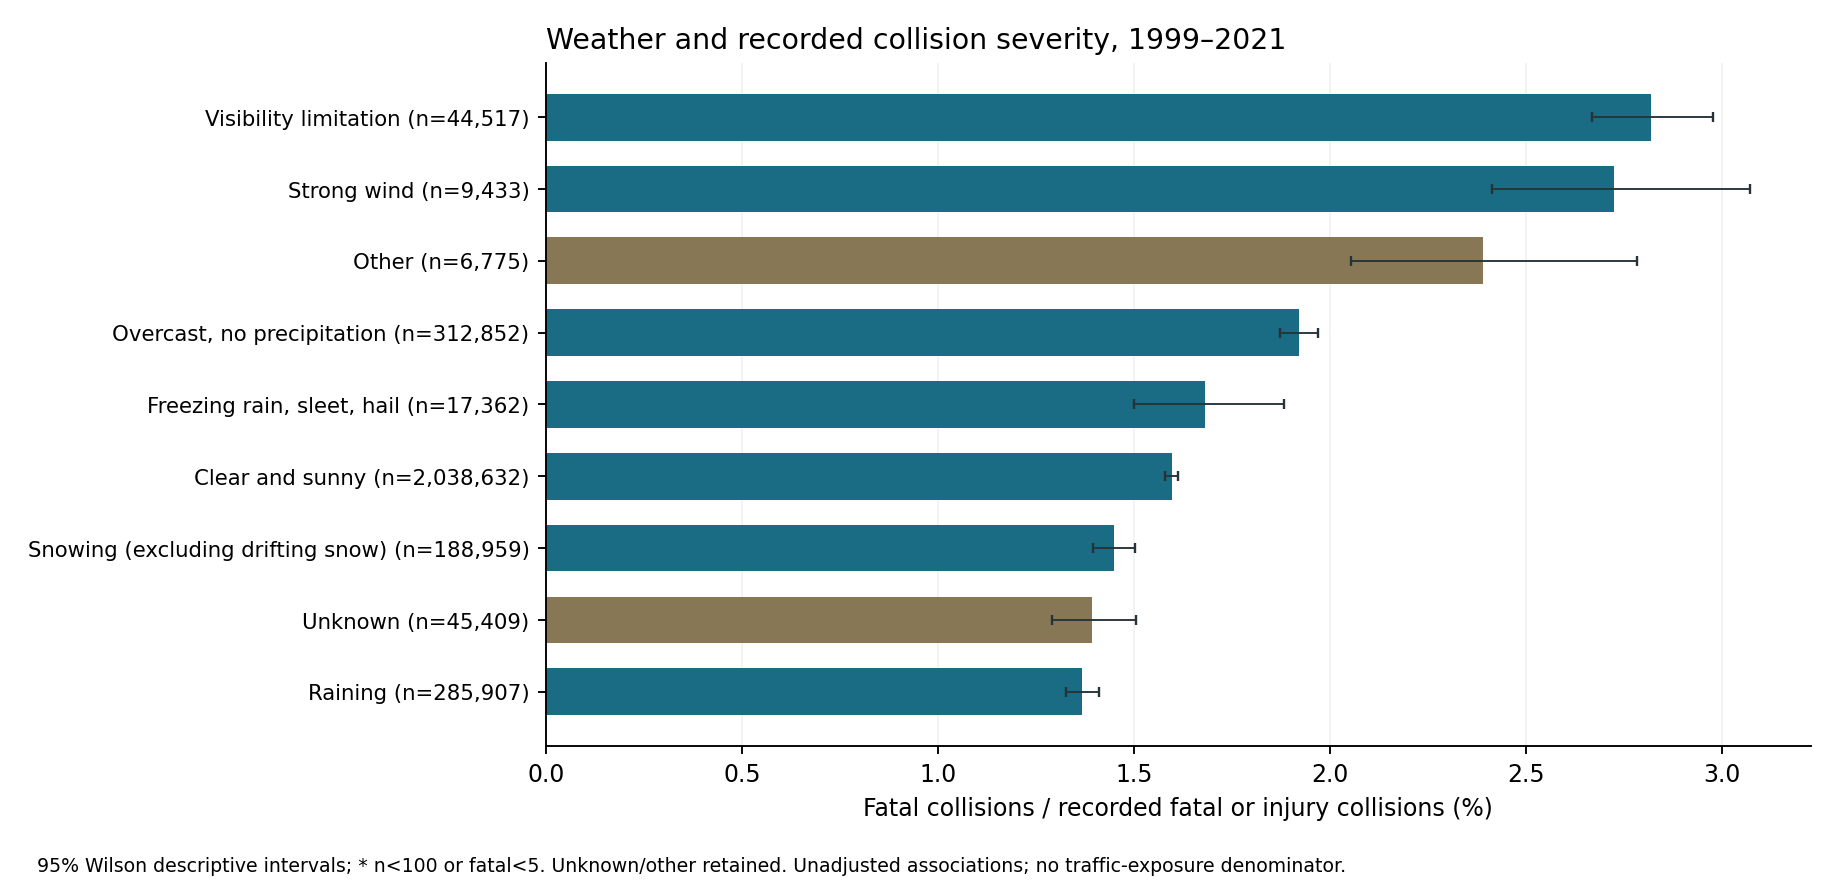

In [9]:
figure('conditions_c_wthr.png')

#### Road surface

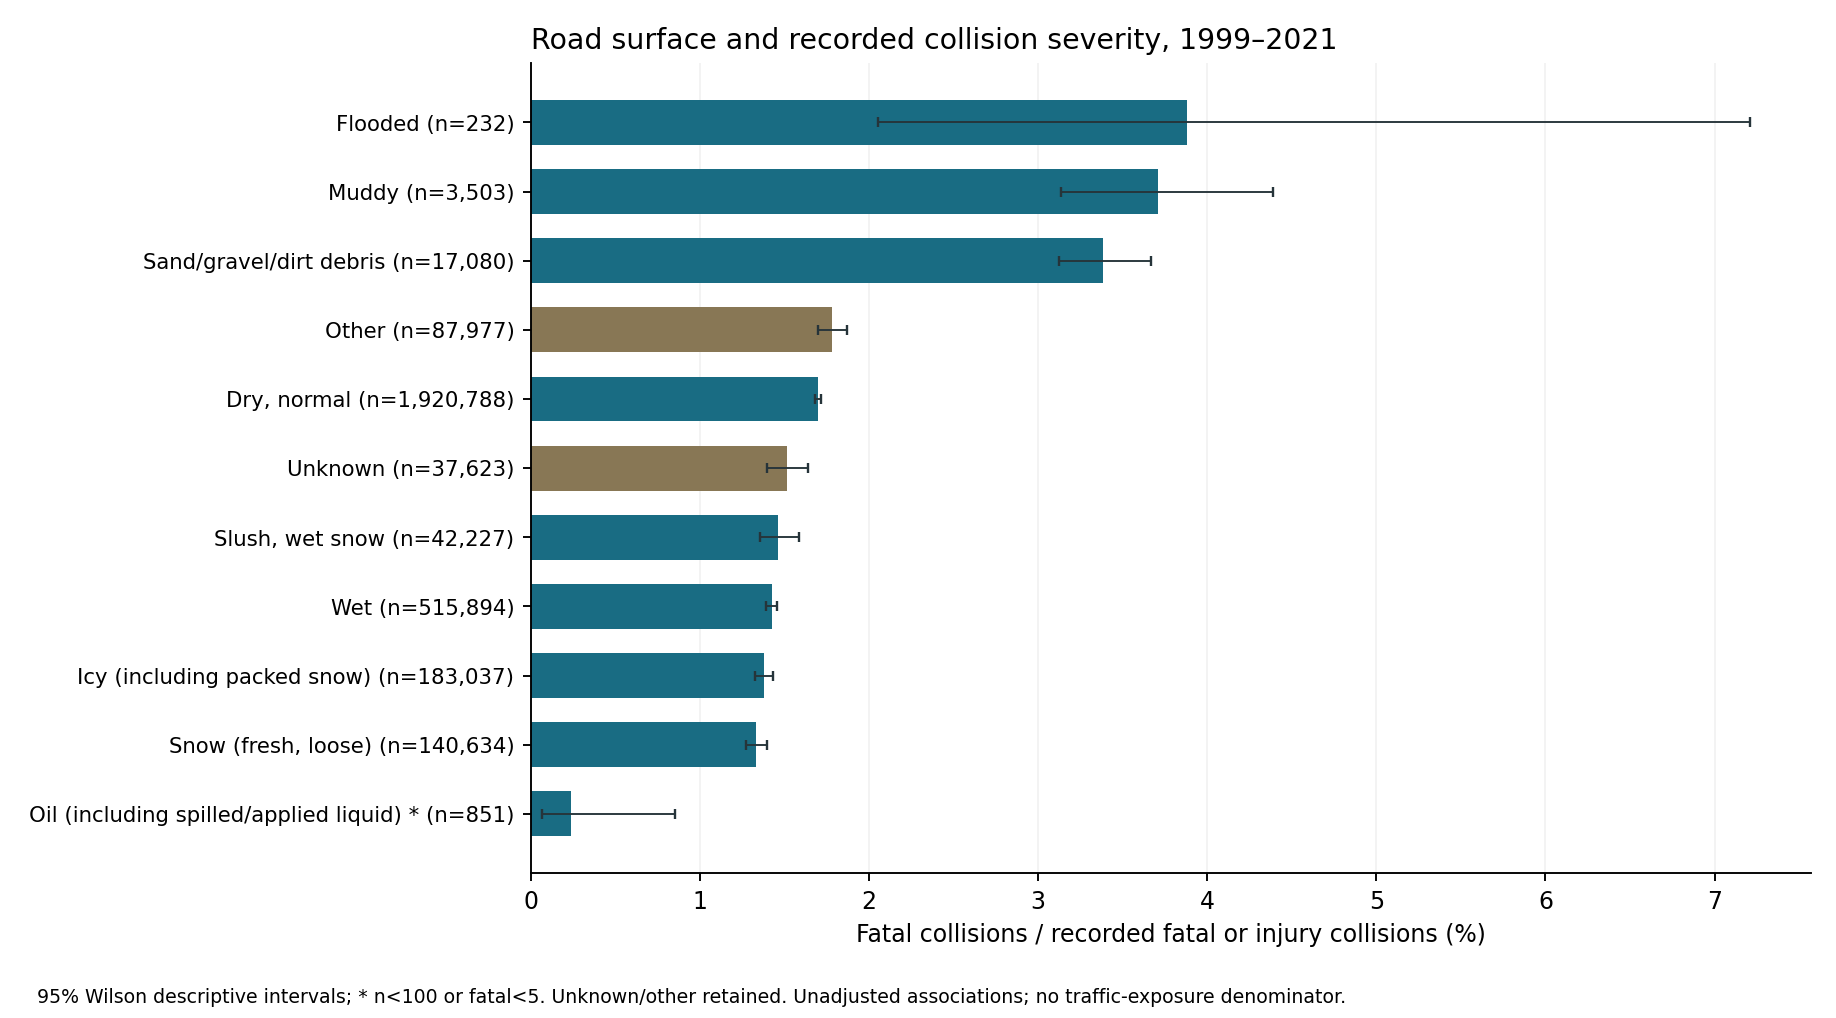

In [10]:
figure('conditions_c_rsur.png')

#### Road alignment

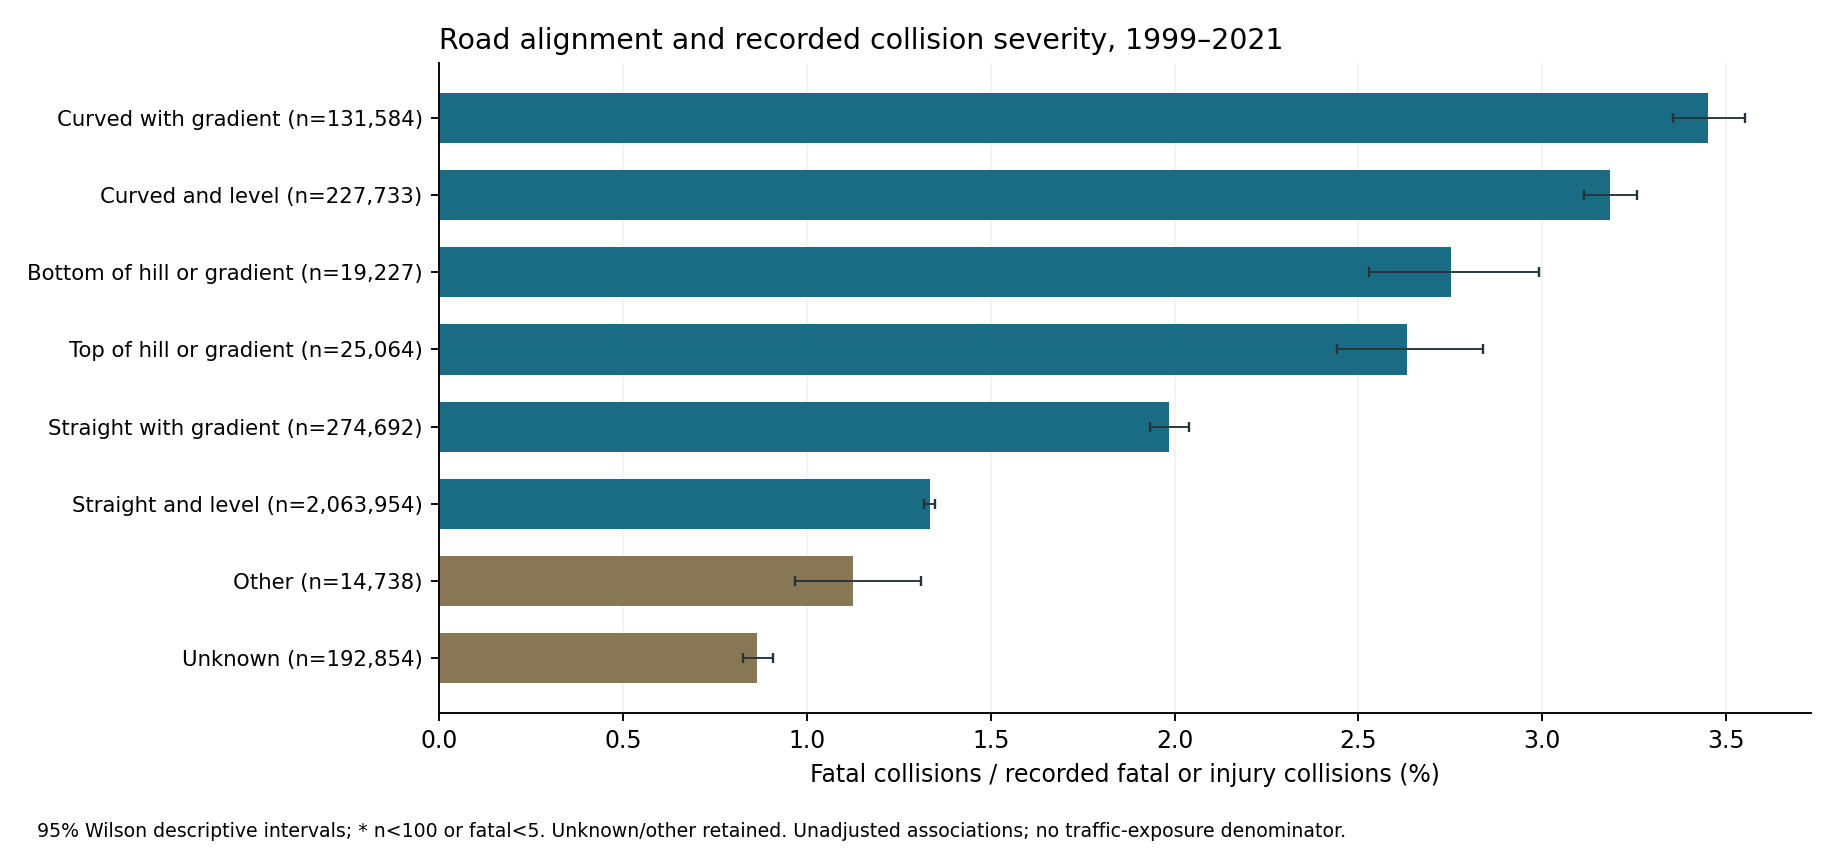

In [11]:
figure('conditions_c_raln.png')

#### Road configuration

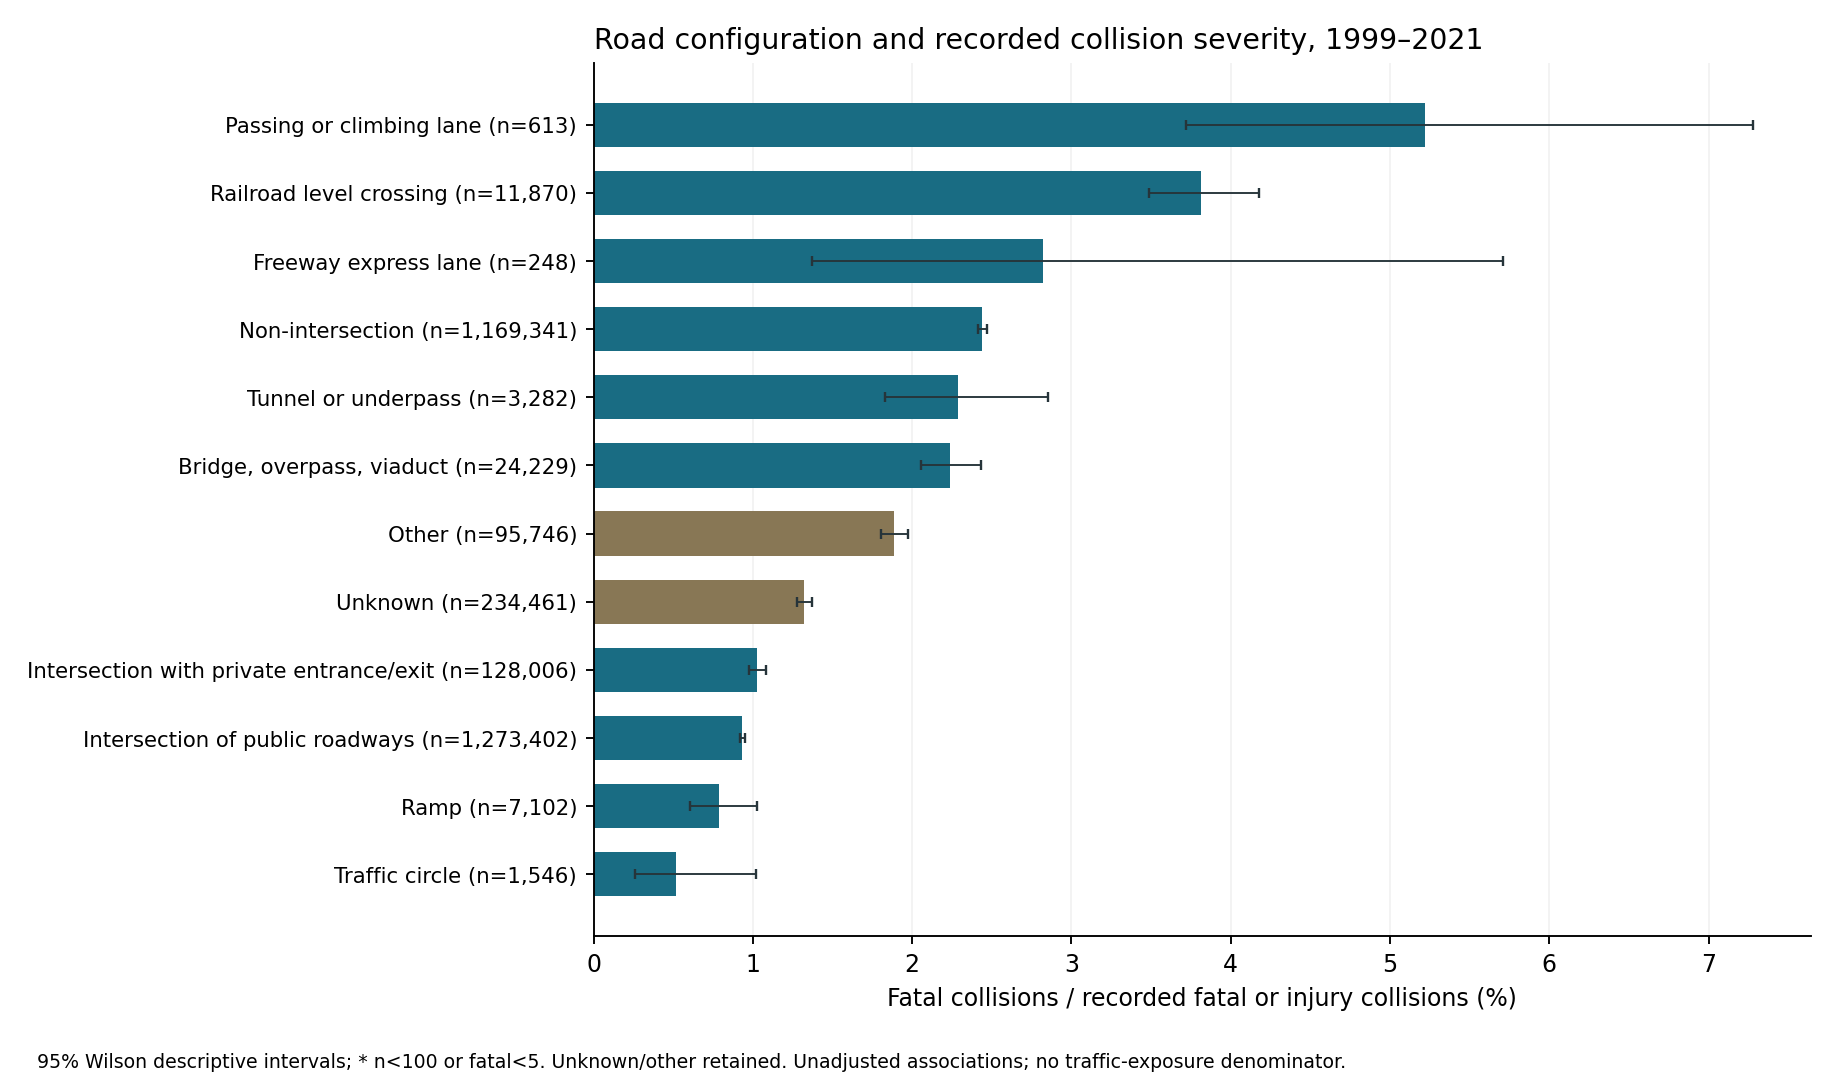

In [12]:
figure('conditions_c_rcfg.png')

#### Traffic control

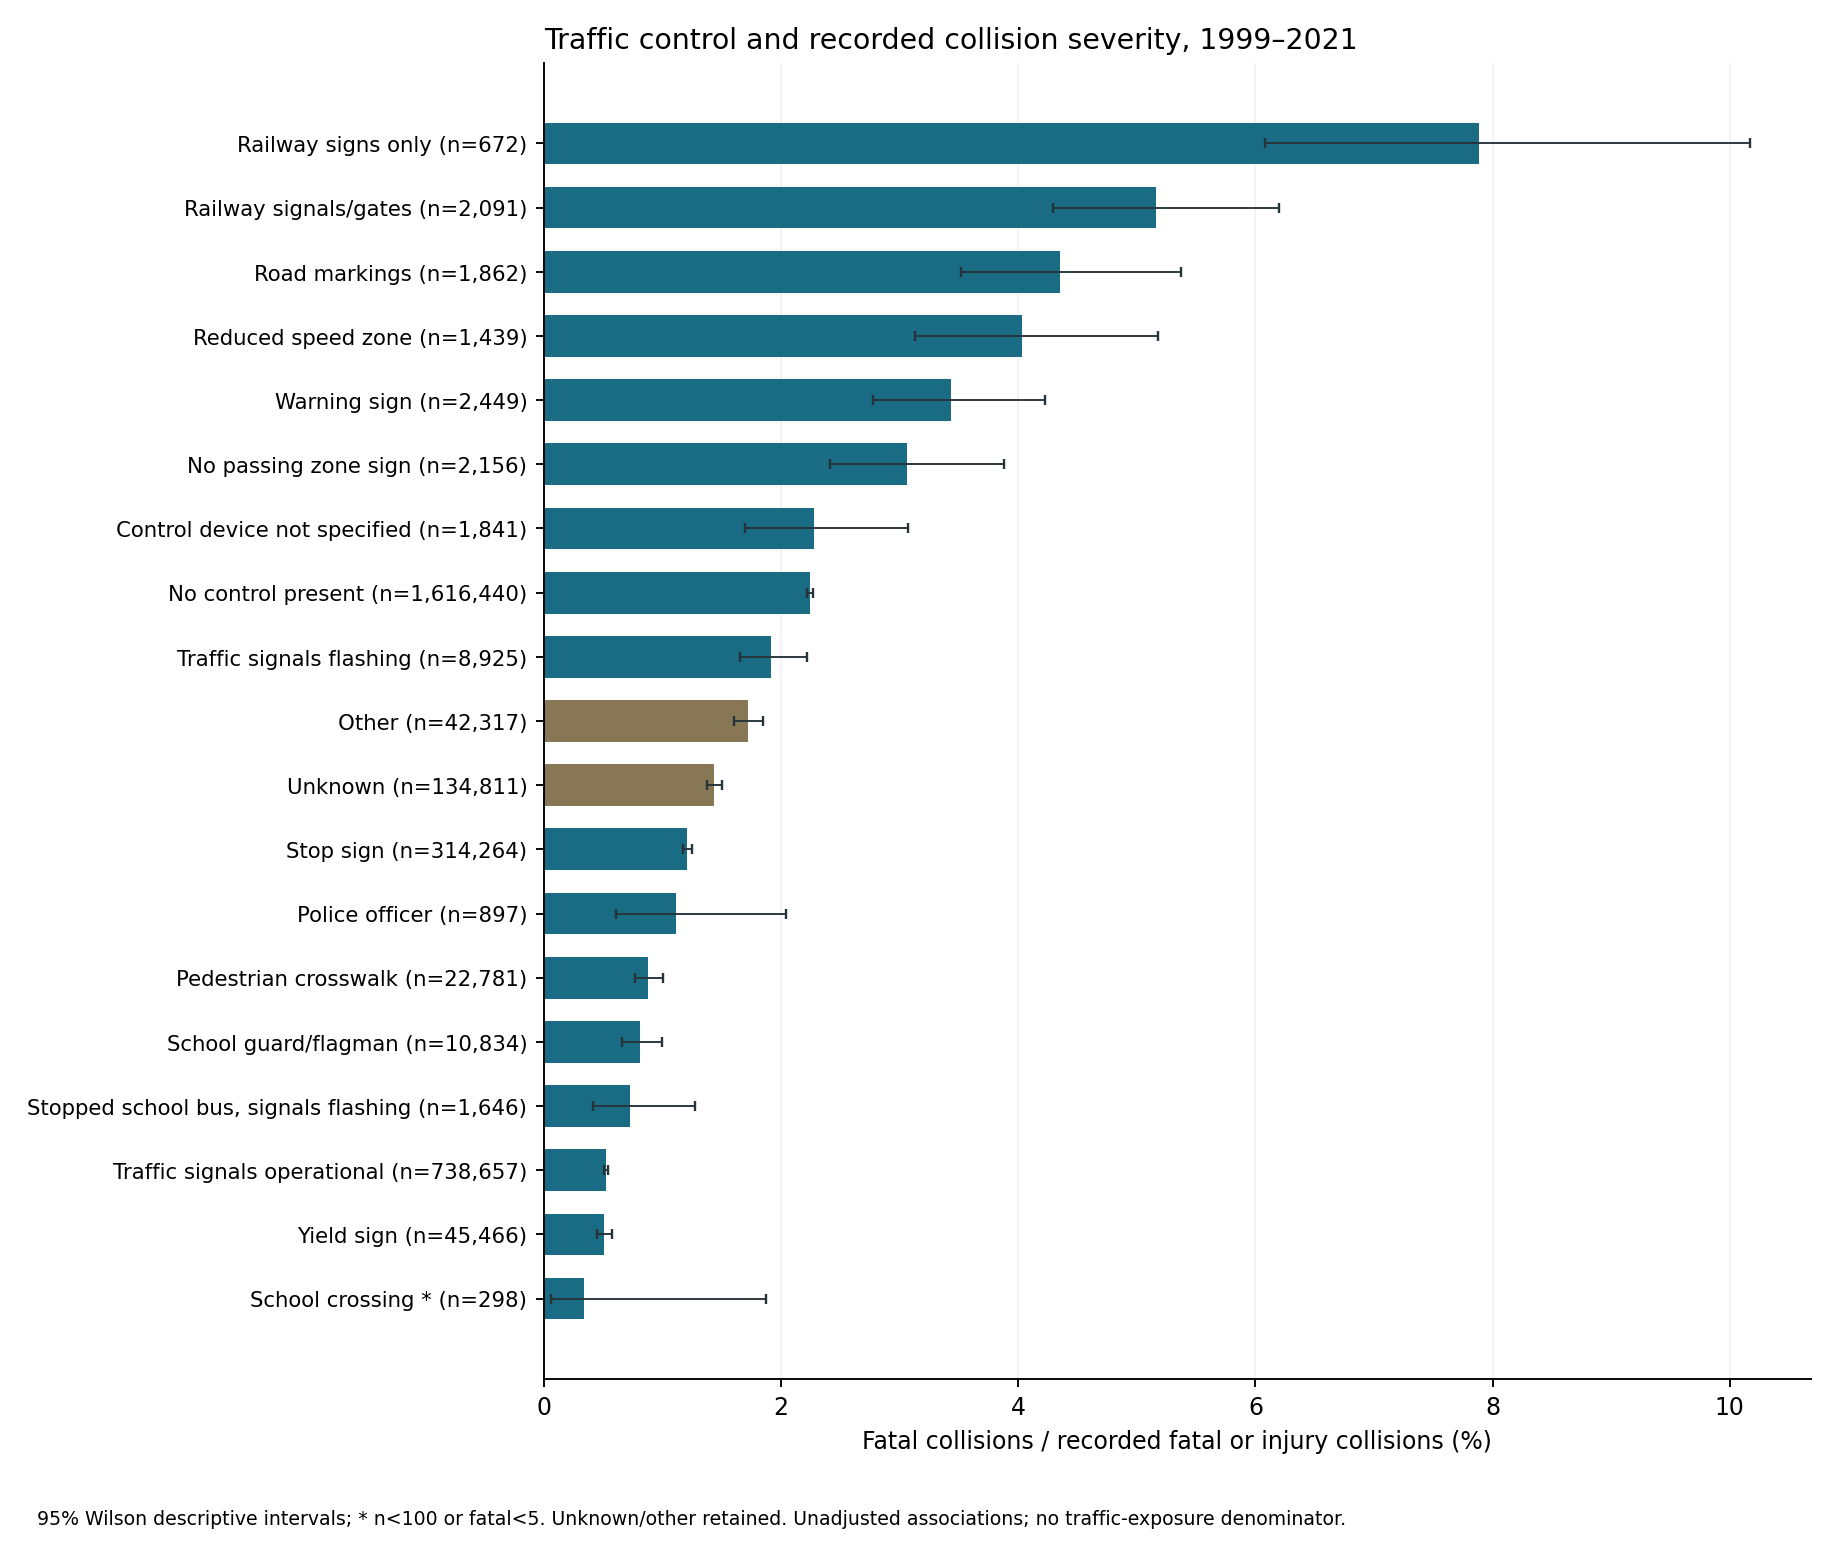

In [13]:
figure('conditions_c_traf.png')

### Year-composition sensitivity

The same annual collision-share weights are applied to every category’s within-year fatal proportions. This removes differences in year composition only. Unsupported categories are withheld when any year is absent; no zero fatal proportion is imputed.

In [14]:
standard = table('eda_condition_year_standardization.csv')
display(standard[standard.all_years_supported].assign(abs_change=lambda d: d.difference_percentage_points.abs()).sort_values('abs_change', ascending=False).head(10).drop(columns='abs_change'))

,field,code,label,years_observed,all_years_supported,observed_sparse_years,any_sparse_year,pooled_fatal_proportion,common_year_weighted_fatal_proportion,difference_percentage_points
37,C_TRAF,16,Railway signs only,23,True,23,True,0.078869,0.083922,0.505332
32,C_TRAF,10,Reduced speed zone,23,True,22,True,0.040306,0.044596,0.428988
6,C_RALN,Q,Other,23,True,8,True,0.011263,0.014237,0.297358
15,C_RCFG,7,Passing or climbing lane,23,True,23,True,0.052202,0.054774,0.257146
5,C_RALN,6,Bottom of hill or gradient,23,True,0,False,0.027513,0.029640,0.212632
43,C_TRAF,5,Warning sign,23,True,17,True,0.034300,0.032248,-0.205144
30,C_RSUR,U,Unknown,23,True,0,False,0.015124,0.016768,0.164427
4,C_RALN,5,Top of hill or gradient,23,True,0,False,0.026333,0.027948,0.161590
33,C_TRAF,11,No passing zone sign,23,True,20,True,0.030612,0.032188,0.157595
45,C_TRAF,7,Police officer,23,True,23,True,0.011148,0.009840,-0.130832


### Missingness and selection

Unknown shares change by year, with road configuration and alignment having the largest pooled unknown proportions. Other is separately observed, not recoded as missing. A complete-case requirement changes both sample size and severity composition; it is diagnostic only.

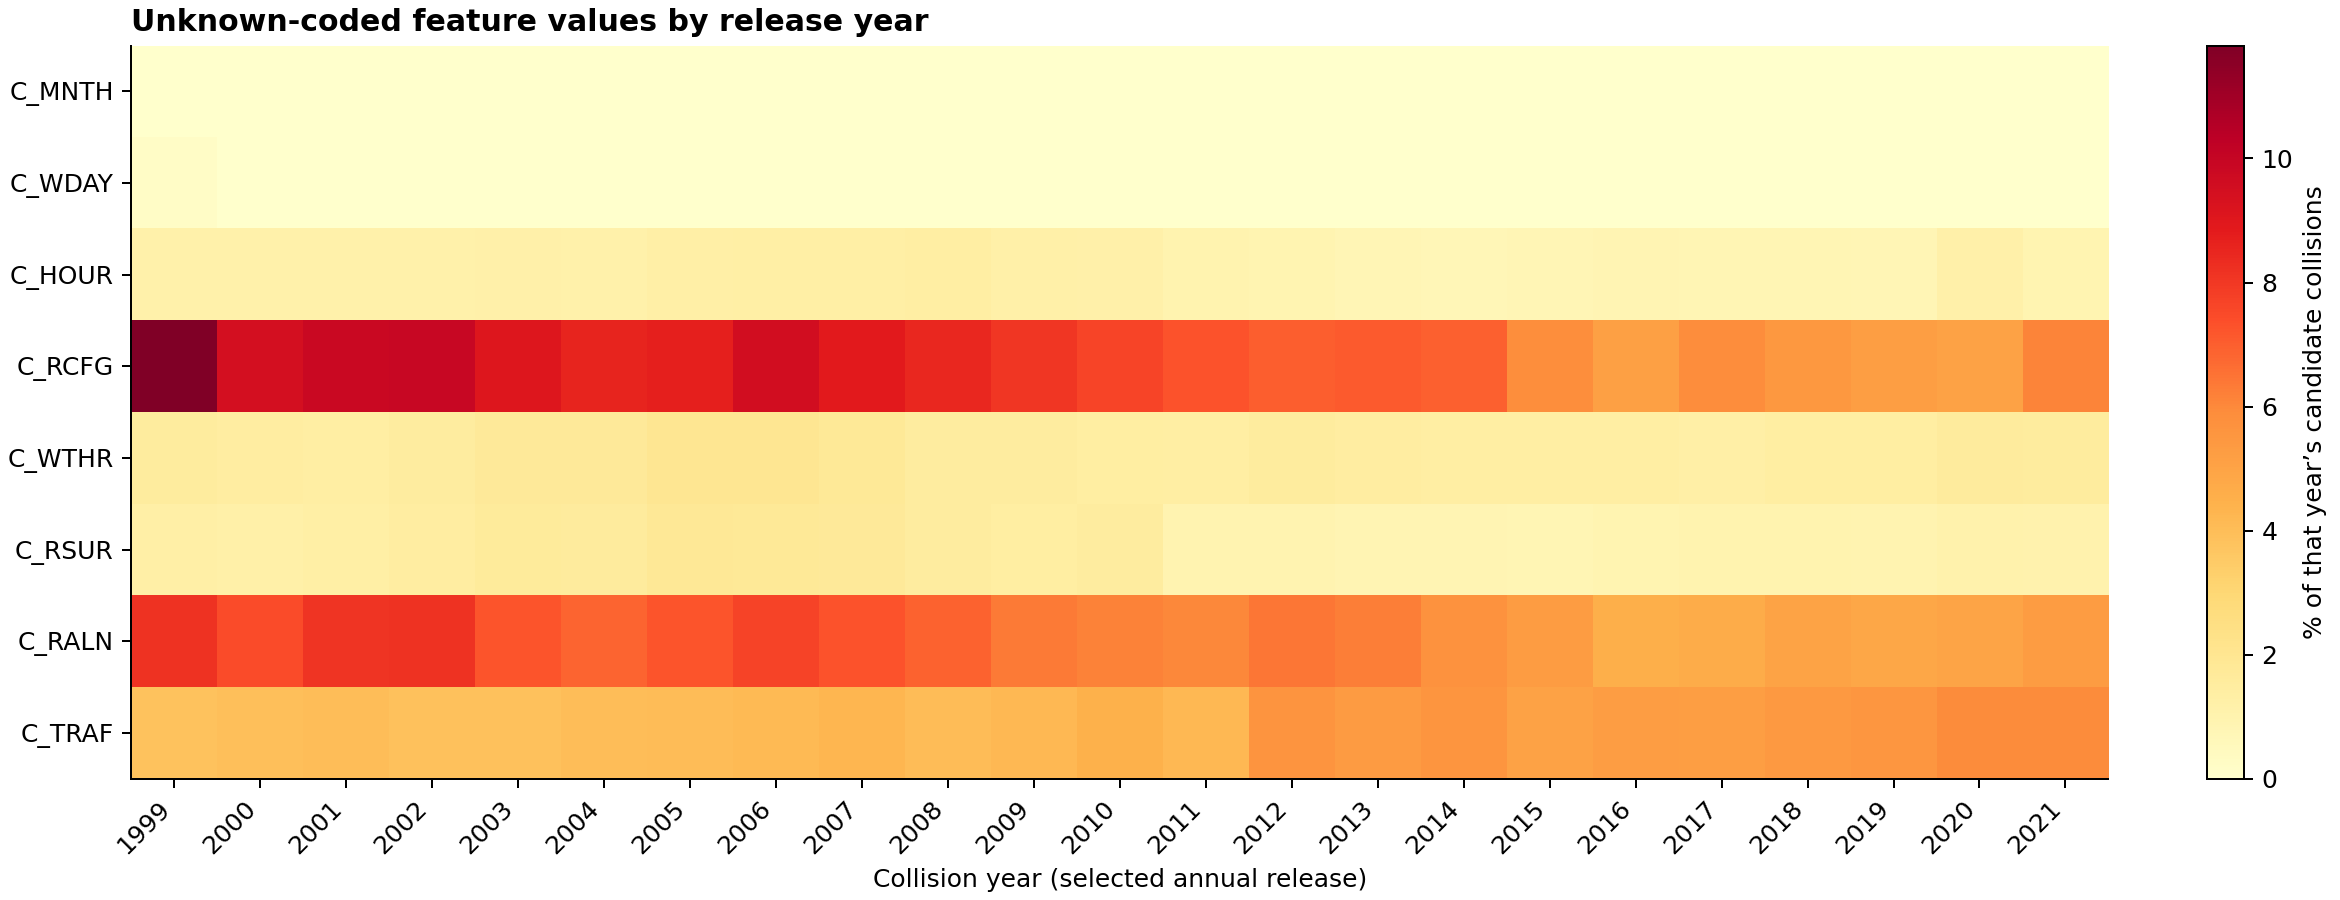

In [15]:
figure('quality_unknown_by_year.png')

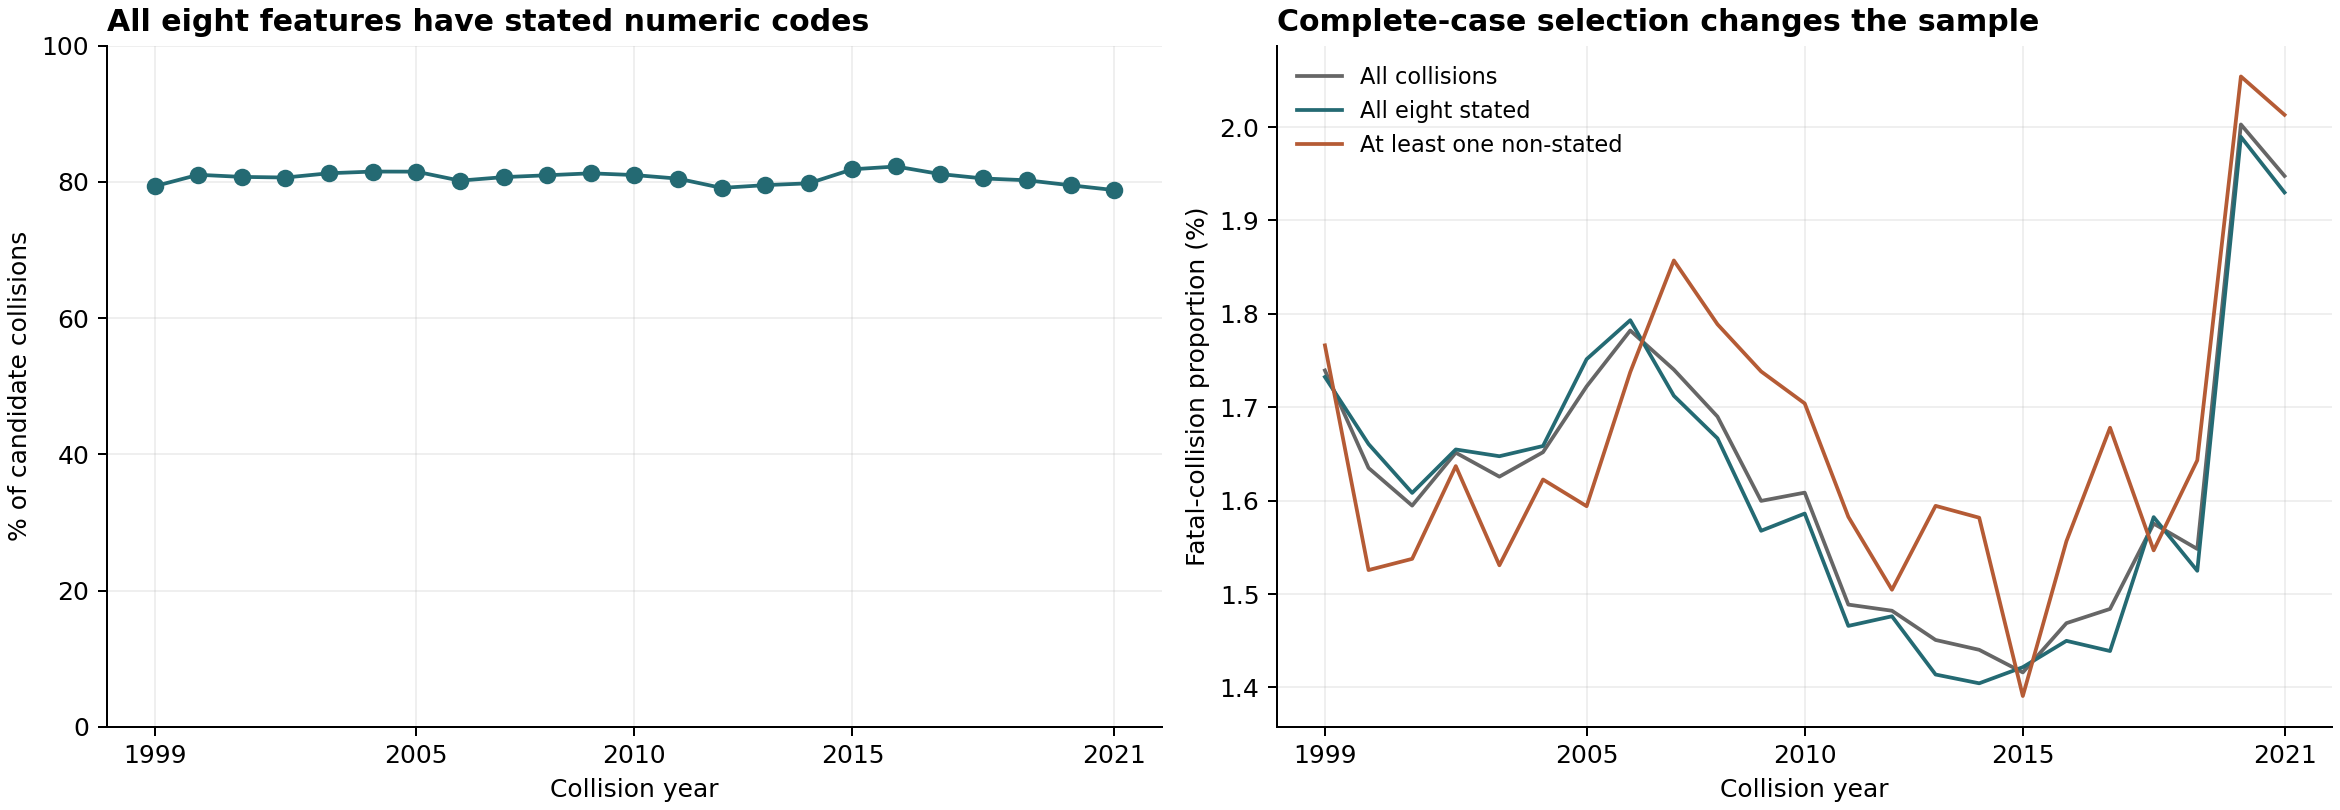

,source_id,year,collisions,fatal_collisions,fully_stated_collisions,fully_stated_fatal_collisions,not_fully_stated_collisions,fully_stated_share,all_fatal_proportion,fully_stated_fatal_proportion,not_fully_stated_fatal_proportion
23,ALL,ALL,2949846,47793,2378300,38354,571546,0.806245,0.016202,0.016127,0.016515


In [16]:
figure('quality_complete_cases.png')
display(table('eda_quality_complete_cases.csv').query("year == 'ALL'"))

### Sparse categories and changing composition

The table counts observed sparse groups separately from supported categories with no observations. These are year-by-feature cells, not unique collisions, and cannot be added to estimate distinct events.

In [17]:
sparse = table('eda_sparse_categories.csv')
sparse_summary = sparse.groupby('field').apply(lambda d: pd.Series({
    'observed_groups': int(d.observed.sum()),
    'observed_sparse_groups': int((d.observed & d['sparse']).sum()),
    'unobserved_supported_groups': int((~d.observed).sum())
}), include_groups=False)
display(sparse_summary)
changes = table('eda_quality_year_changes.csv')
display(changes.loc[changes.groupby('field').total_variation_distance.idxmax()].sort_values('field'))

,observed_groups,observed_sparse_groups,unobserved_supported_groups
field,,,
C_HOUR,575,0,23
C_MNTH,299,23,23
C_RALN,184,8,23
C_RCFG,263,94,82
C_RSUR,250,50,26
C_TRAF,433,223,50
C_WDAY,184,23,23
C_WTHR,207,6,23


,field,previous_year,year,total_variation_distance,largest_shift_code,largest_shift_percentage_points
20,C_HOUR,2019,2020,0.024690,8,-0.971048
43,C_MNTH,2020,2021,0.070337,1,-4.054795
54,C_RALN,2009,2010,0.026917,1,1.301680
66,C_RCFG,1999,2000,0.030788,UU,-2.383010
103,C_RSUR,2014,2015,0.046552,1,4.650568
122,C_TRAF,2011,2012,0.020934,18,-1.880706
140,C_WDAY,2007,2008,0.014459,1,-0.760459
161,C_WTHR,2006,2007,0.044540,3,-3.271793


## Takeaways

1. Keep counts and conditional severity separate: their temporal peaks differ.
2. Use condition differences as hypotheses for adjusted severity analysis, not evidence of causation or crash-occurrence risk. Rare categories need explicit caution.
3. Keep unknown/other categories and all valid targets. Complete-case deletion would change the population substantially.
4. Inspect annual condition tables and late-period stability before accepting pooled associations as persistent.

**Next step:** freeze chronological development/validation/test periods, metrics and categorical handling before fitting a prevalence baseline and interpretable severity model. Evaluate discrimination, fatal-class recall/precision, calibration and performance by source year. Keep occurrence modeling and geographic acquisition as separate phases.

**Validation:** independent full-cohort reconciliations and focused regression tests accompany this notebook. Standalone chart images were visually inspected; a rendered whole-notebook page preview remains unverified because local browser preview was blocked by the recorded URL policy. Successful notebook execution is checked separately from visual inspection. No model is trained here.